In [ ]:
import os
import random
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
import torch.utils.data
import torchvision.datasets as dset
import torchvision.transforms as transforms

from tqdm import tqdm
from torchvision import transforms
from torchvision.utils import save_image, make_grid

import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive

drive.mount("/content/drive")
device_config = torch.device("cuda:0" if (torch.cuda.is_available()) else "cpu")
print(device_config)

In [ ]:
!unzip '/content/drive/MyDrive/GAN/anime_images.zip' -d'/content/images'

Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
  inflating: /content/images/anime_images/images/62764_2019.jpg  
  inflating: /content/images/anime_images/images/62765_2019.jpg  
  inflating: /content/images/anime_images/images/62766_2019.jpg  
  inflating: /content/images/anime_images/images/62767_2019.jpg  
  inflating: /content/images/anime_images/images/62768_2019.jpg  
  inflating: /content/images/anime_images/images/62769_2019.jpg  
  inflating: /content/images/anime_images/images/6276_2003.jpg  
  inflating: /content/images/anime_images/images/62770_2019.jpg  
  inflating: /content/images/anime_images/images/62771_2019.jpg  
  inflating: /content/images/anime_images/images/62772_2019.jpg  
  inflating: /content/images/anime_images/images/62773_2019.jpg  
  inflating: /content/images/anime_images/images/62774_2019.jpg  
  inflating: /content/images/anime_images/images/62775_2019.jpg  
  inflating: /content/images/anime_images/images/62776_2019.jpg  

In [ ]:
batch_quantity = 64
img_dimension = 64

# Create the dataset
anime_data = dset.ImageFolder(root = '/content/images',
    transform = transforms.Compose([
        transforms.Resize(img_dimension),
        transforms.CenterCrop(img_dimension),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ]))

# Create the dataloader
data_loader = torch.utils.data.DataLoader(
    anime_data,
    batch_size = batch_quantity,
    shuffle = True,
    num_workers = 2,
    drop_last = True
)

print(f"Le nombre de batchs= : {len(data_loader)}")
print(f"Le nombre total d'images= : {len(anime_data)}")

Le nombre de batchs= : 993
Le nombre total d'images= : 63565


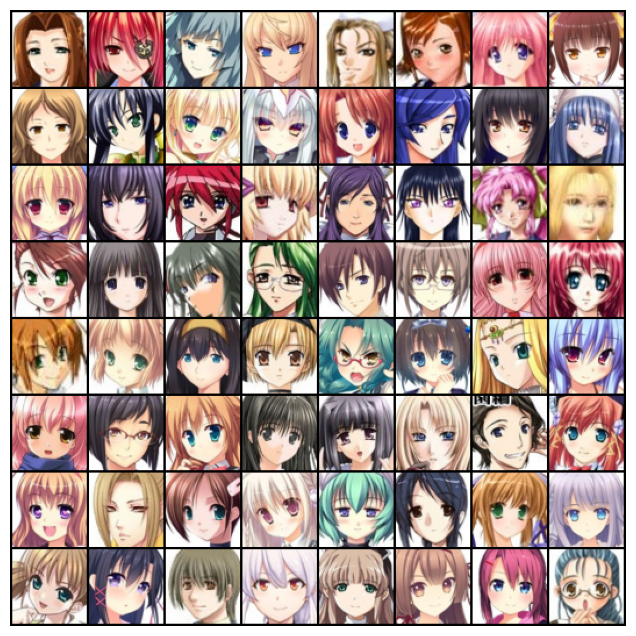

In [ ]:
def display_image_grid(images):
    images = images / 2 + 0.5
    image_grid = make_grid(images, 8)
    image_grid = image_grid.permute(1, 2, 0)
    image_grid = image_grid.cpu().numpy()
    plt.imshow(image_grid)
    plt.xticks([])
    plt.yticks([])
    plt.show()
    plt.close()

sample_batch = next(iter(data_loader))
plt.figure(figsize = (8 , 8))
plt.axis("off")

display_image_grid(sample_batch[0] )



In [ ]:
def initialize_weights(module):
    module_name = module.__class__.__name__

    if module_name.find('Conv') != -1:
        nn.init.normal_(module.weight.data, 0.0, 0.02)
    elif module_name.find('BatchNorm') != -1:
        nn.init.normal_(module.weight.data, 1.0, 0.02)
        nn.init.constant_(module.bias.data, 0)

In [ ]:


# Number of channels in the training images. For color images this is 3
num_channels = 3

# Size of z latent vector
z_dim = 100

# Size of feature maps in generator
gen_feature_size = 64

# Size of feature maps in discriminator
disc_feature_size = 64

# Number of training epochs
epoch_count = 50

# Learning rate for optimizers
learning_rate = 0.0002



In [ ]:

class GeneratorNetwork(nn.Module):
    def __init__(self):
        super(GeneratorNetwork, self).__init__()

        self.model = nn.Sequential(
            nn.ConvTranspose2d(z_dim, gen_feature_size * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(gen_feature_size * 8),
            nn.ReLU(True),

            nn.ConvTranspose2d(gen_feature_size * 8, gen_feature_size * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(gen_feature_size * 4),
            nn.ReLU(True),

            nn.ConvTranspose2d(gen_feature_size * 4, gen_feature_size * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(gen_feature_size * 2),
            nn.ReLU(True),

            nn.ConvTranspose2d(gen_feature_size * 2, gen_feature_size, 4, 2, 1, bias=False),
            nn.BatchNorm2d(gen_feature_size),
            nn.ReLU(True),

            nn.ConvTranspose2d(gen_feature_size, num_channels, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, input_data):
        return self.model(input_data)


net_generator = GeneratorNetwork().to(device_config)
net_generator.apply(initialize_weights)
print(net_generator)

GeneratorNetwork(
  (model): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh(

In [ ]:

class DiscriminatorNetwork(nn.Module):
    def __init__(self):
        super(DiscriminatorNetwork, self).__init__()

        self.model = nn.Sequential(
            nn.Conv2d(num_channels, disc_feature_size, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(disc_feature_size, disc_feature_size * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(disc_feature_size * 2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(disc_feature_size * 2, disc_feature_size * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(disc_feature_size * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(disc_feature_size * 4, disc_feature_size * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(disc_feature_size * 8),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(disc_feature_size * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, input_data):
        return self.model(input_data)

net_discriminator = DiscriminatorNetwork().to(device_config)
net_discriminator.apply(initialize_weights)
print(net_discriminator)

DiscriminatorNetwork(
  (model): Sequential(
    (0): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (9): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2, inplace=True)
    (11): Conv2d(512, 1, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (12): Sigmoid()
  )
)


In [ ]:
latent_vector = torch.randn(64, z_dim, 1, 1, device=device_config)
sample_output = net_generator(latent_vector)
sample_output


tensor([[[[ 2.6343e-02,  3.5119e-02,  1.1253e-02,  ..., -2.5365e-02,
            3.4637e-02,  5.5498e-02],
          [-5.6307e-02,  1.6757e-01,  5.2392e-02,  ...,  7.6086e-02,
            2.5691e-02,  6.4919e-02],
          [ 6.5926e-02,  1.9803e-01,  7.4108e-02,  ..., -1.5781e-01,
            2.9199e-01, -2.4210e-03],
          ...,
          [-1.6441e-03, -1.5968e-01, -9.2681e-02,  ..., -2.3531e-02,
            3.2714e-02,  7.3746e-02],
          [ 1.3925e-02, -2.7335e-02,  2.4963e-01,  ..., -7.2045e-02,
            2.8075e-01, -4.3321e-02],
          [ 1.8204e-02,  6.9110e-02, -4.2526e-02,  ..., -1.8031e-02,
           -4.2978e-02,  5.6444e-02]],

         [[-6.8727e-03, -4.7622e-03,  4.5802e-03,  ...,  7.4140e-03,
           -6.3748e-02, -8.4716e-03],
          [ 1.3316e-01, -2.0187e-02,  1.1746e-01,  ...,  2.9816e-02,
            1.4767e-02,  2.5489e-02],
          [-8.5794e-02, -6.8774e-02, -5.9958e-02,  ...,  2.7982e-01,
            1.5491e-01,  2.7420e-02],
          ...,
     

In [ ]:
sample_output.shape

torch.Size([64, 3, 64, 64])

Random generated output can be visualised individually or in batches

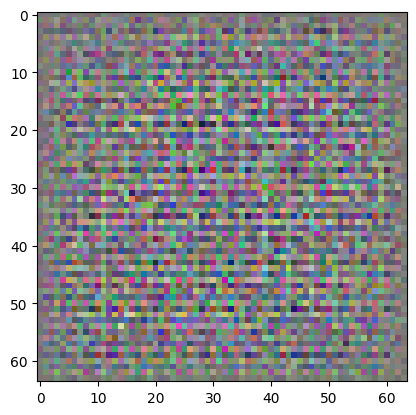

In [ ]:
plt.imshow(np.transpose(make_grid(sample_output[0].to(device_config), padding=2, normalize=True).cpu(), (1, 2, 0)))

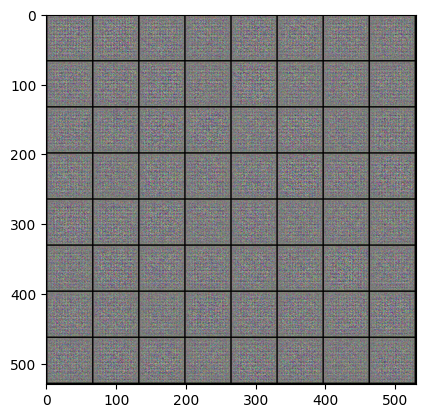

In [ ]:
plt.imshow(np.transpose(make_grid(sample_output.to(device_config), padding=2, normalize=True).cpu(), (1, 2, 0)))

In [ ]:
net_discriminator.eval()

with torch.no_grad():
    prediction = net_discriminator(sample_output)

print(prediction[:10])

tensor([[[[0.4999]]],


        [[[0.5002]]],


        [[[0.4977]]],


        [[[0.4997]]],


        [[[0.5001]]],


        [[[0.5026]]],


        [[[0.5002]]],


        [[[0.5005]]],


        [[[0.4984]]],


        [[[0.4985]]]], device='cuda:0')


In [ ]:

loss_function = nn.BCELoss()

fixed_latent = torch.randn(64, z_dim, 1, 1, device=device_config)

real_label_val = 1.
fake_label_val = 0.

optimizer_discriminator = optim.Adam(net_discriminator.parameters(), lr=learning_rate, betas=(0.5, 0.999))
optimizer_generator = optim.Adam(net_generator.parameters(), lr=learning_rate, betas=(0.5, 0.999))

In [ ]:

for epoch in tqdm(range(epoch_count)):
    for idx, dataset in enumerate(data_loader, 0):

        net_discriminator.zero_grad()

        real_imgs = dataset[0].to(device_config)
        real_img_labels = torch.full((batch_quantity,), real_label_val, dtype=torch.float, device=device_config)

        real_output = net_discriminator(real_imgs).view(-1)
        disc_real_loss = loss_function(real_output, real_img_labels)
        disc_real_loss.backward()

        mean_real_score = real_output.mean().item()

        noise_vec = torch.randn(batch_quantity, z_dim, 1, 1, device=device_config)

        generated_imgs = net_generator(noise_vec)
        fake_img_labels = torch.full((batch_quantity,), fake_label_val, dtype=torch.float, device=device_config)

        fake_output = net_discriminator(generated_imgs.detach()).view(-1)
        disc_fake_loss = loss_function(fake_output, fake_img_labels)
        disc_fake_loss.backward()

        mean_fake_score = fake_output.mean().item()


        optimizer_discriminator.step()

        net_generator.zero_grad()

        output = net_discriminator(generated_imgs).view(-1)
        gen_loss = loss_function(output, real_img_labels)
        gen_loss.backward()
        optimizer_generator.step()

        if (idx % 200 == 0) or ((epoch == epoch_count - 1) and (idx == len(data_loader) - 1)):
            print(f"""Epoch {epoch+1}: - Step: {idx} |
                      D_real Loss: {disc_real_loss:.3f} |
                      D_fake Loss: {disc_fake_loss:.3f} |
                      G_Loss: {gen_loss:.3f} |
                      Real_score {mean_real_score:.3f} |
                      Fake_score {mean_fake_score:.3f}
            """)

            with torch.no_grad():
                fake_imgs_display = net_generator(fixed_latent).reshape(batch_quantity, 3, 64, 64).detach().cpu()
                display_image_grid(fake_imgs_display )


full_discriminator_model_path = "/content/drive/MyDrive/Ch16/discriminator_model.pth"
torch.save(net_discriminator, full_discriminator_model_path)
print(f"Le modèle complet du discriminator a été sauvegardé dans le fichier : {full_discriminator_model_path}")

full_generator_model_path = "/content/drive/MyDrive/Ch16/generator_model.pth"
torch.save(net_generator, full_generator_model_path)
print(f"Le modèle complet du générateur a été sauvegardé dans le fichier : {full_generator_model_path}")



Output hidden; open in https://colab.research.google.com to view.

In [ ]:

net_generator_loaded = torch.load("/content/drive/MyDrive/Ch16/generator_model.pth")
net_generator_loaded.eval()
print("Le modèle complet du générateur a été chargé avec succès.")


net_discriminator_loaded = torch.load("/content/drive/MyDrive/Ch16/discriminator_model.pth")
net_discriminator_loaded.eval()
print("Le modèle complet du discriminator a été chargé avec succès.")


<ipython-input-16-0ad25aaa92bd>:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net_generator_loaded = torch.load("/content/drive/MyDrive/Ch16/generator_model.pth")
<ipytho

Le modèle complet du générateur a été chargé avec succès.
Le modèle complet du discriminator a été chargé avec succès.


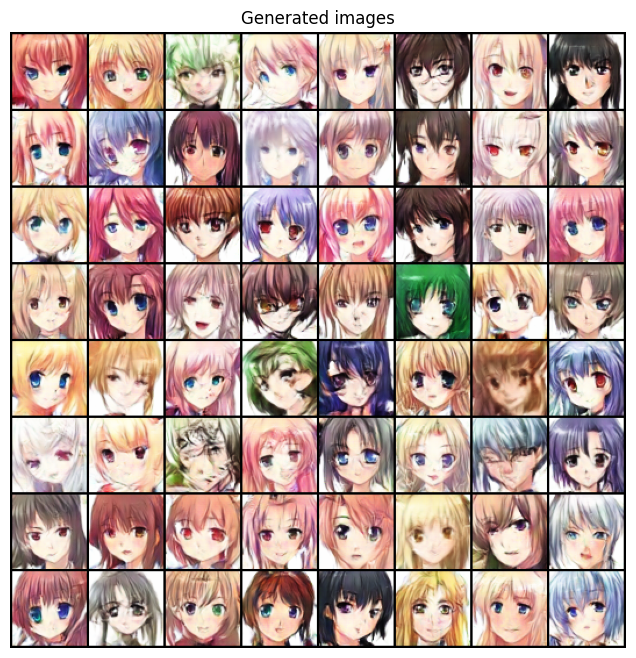

In [ ]:
noise_vec = torch.randn(64, z_dim, 1, 1, device=device_config)

new_generatedimgs = net_generator_loaded(noise_vec).reshape(64, 3, 64, 64).detach()
plt.figure(figsize = (8 , 8))
plt.axis("off")
plt.title("Generated images")

display_image_grid(new_generatedimgs)

In [ ]:

prediction = net_discriminator_loaded(new_generatedimgs)

mean=prediction.mean().item()
std=prediction.std().item()
p_max = prediction.max().item()
idx_max = prediction.argmax().item()
print(f"La probabilité moyenne = {mean}")
print(f"L'écart-type = {std}")

print(f"La probabilité max = {p_max}")
print(f"L'indice associé à l'image avec la probabilité max = {idx_max}")


La probabilité moyenne = 0.17661583423614502
L'écart-type = 0.23890314996242523
La probabilité max = 0.9324998259544373
L'indice associé à l'image avec la probabilité max = 54
